# Apprentissage supervisé : KNN, SVM, Random Forest

**Objectif** : prédire la **classe** (Low / Medium / High) de la température à 2 m du **mois suivant**.

**Données** (créées par `04_Feature_Engineering.ipynb`) : le train, le test, un échantillon du train (30 000 lignes) et la liste des jeux de variables.

**Étapes**
1. Charger les données et vérifier qu'elles sont correctes
2. Calculer deux baselines (des modèles très simples à battre)
3. Préparer la validation chronologique
4. Choisir le jeu de variables
5. Régler les modèles (KNN, SVM, Random Forest) et **enregistrer chaque modèle** dans `results/models/<configuration>/`
6. Recharger **tous** les modèles enregistrés et les évaluer sur le test, chacun avec les variables de son entraînement

On peut enchaîner plusieurs configurations (jeu de variables, avec ou sans `year`, échantillon ou train complet). Le test n'est lancé qu'à la fin : il ne dépend pas de ce qui est encore en mémoire.

### Vocabulaire
- **Validation chronologique** : on s'entraîne sur les mois passés et on vérifie sur les mois suivants, comme dans la vraie prévision.
- **Macro-F1** : un score entre 0 et 1 qui donne le même poids aux 3 classes. Il est plus honnête que l'accuracy quand une classe est rare.
- **class_weight** : donne plus d'importance aux erreurs sur la classe rare (Low) pendant l'entraînement.

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# Dossier des données
BASE = os.environ.get("DM_BASE", r"C:\Users\chahi\Desktop\DM-Weather-framework\data")
# BASE = os.environ.get("DM_BASE", r"D:\M2\Data Mining\DM-Weather-framework\data")
SUP_DIR = os.path.join(BASE, "processed", "transformed", "supervised")
RES_DIR = r"C:\Users\chahi\Desktop\DM-Weather-framework\results"
RESULTAT = RES_DIR
TABLES_DIR = os.path.join(RESULTAT, "tables")
FIGURES_DIR = os.path.join(RESULTAT, "figures")
MODELES_DIR = os.path.join(RESULTAT, "models")
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELES_DIR, exist_ok=True)

LABELS = ["Low", "Medium", "High"]   # les 3 classes
SEED = 42                            # pour retrouver les mêmes résultats à chaque exécution

## 1. Chargement et vérifications

In [2]:
train  = pd.read_parquet(os.path.join(SUP_DIR, "train_supervised.parquet"))
test   = pd.read_parquet(os.path.join(SUP_DIR, "test_supervised.parquet"))
sample = pd.read_parquet(os.path.join(SUP_DIR, "train_sample_30k.parquet"))
class_edges  = json.load(open(os.path.join(SUP_DIR, "class_edges.json")))

# Les 4 jeux de variables (complet, reduit, reduit_sans_sp, strict_cours)
FEATURE_SETS = json.load(open(os.path.join(SUP_DIR, "feature_sets.json")))

# Les classes en texte, les dates au format date
for d in (train, test, sample):
    d["classe"] = d["classe"].astype(str)
    d["date"] = pd.to_datetime(d["date"])
sample = sample.reset_index(drop=True)

print("Train :", train.shape, "| Test :", test.shape, "| Échantillon :", sample.shape)
print("Bornes des classes (train) :", np.round(class_edges["bornes_train"], 2))
print("Jeux de variables :", {k: len(v) for k, v in FEATURE_SETS.items()})

Train : (602175, 18) | Test : (151900, 18) | Échantillon : (30000, 18)
Bornes des classes (train) : [ 0.28 13.86 27.44 41.03]
Jeux de variables : {'complet': 14, 'reduit': 12, 'reduit_sans_sp': 11, 'strict_cours': 11}


In [3]:
# Vérification 1 : la cible ne doit JAMAIS être dans les variables d'entrée (sinon le modèle triche)
colonnes_interdites = ["classe", "t2m_next", "month", "date"]
for nom, cols in FEATURE_SETS.items():
    assert not set(cols) & set(colonnes_interdites), "Problème dans le jeu " + nom

# Vérification 2 : la cible du dernier mois du train ne doit pas tomber dans le test
derniere_cible_train = train["date"].max() + pd.DateOffset(months=1)
print("Train : de", train["date"].min().date(), "à", train["date"].max().date(),
      "(cibles jusqu'à", derniere_cible_train.date(), ")")
print("Test  : de", test["date"].min().date(), "à", test["date"].max().date())
if test["date"].min() <= derniere_cible_train:
    print("ATTENTION : chevauchement entre le train et le test !")
else:
    print("OK : pas de chevauchement entre le train et le test.")

# Vérification 3 : pourcentage de chaque classe
pourcentages = pd.concat({
    "train": train["classe"].value_counts(normalize=True),
    "echantillon": sample["classe"].value_counts(normalize=True),
    "test": test["classe"].value_counts(normalize=True),
}, axis=1).reindex(LABELS) * 100
display(pourcentages.round(1))

Train : de 2015-01-01 à 2024-03-01 (cibles jusqu'à 2024-04-01 )
Test  : de 2024-05-01 à 2026-08-01
OK : pas de chevauchement entre le train et le test.


,train,echantillon,test
classe,,,
Low,16.2,16.2,13.3
Medium,45.0,45.0,38.9
High,38.8,38.8,47.8


## 2. Baselines

Deux références simples que les modèles doivent battre :
- **classe majoritaire** du train ;
- **classe majoritaire par mois** (calculée sur le train) : une baseline saisonnière, bien plus exigeante.

**les fonctions d'evaluations** :
 -  Macro-F1 = moyenne non pondérée des F1 de Low, Medium et High (F1 = moyenne harmonique de la précision et du rappel). Chaque classe compte autant : une classe rare mal prédite fait baisser le score, contrairement à l'accuracy, qu'un modèle prédisant toujours Medium porte déjà à ≈ 45 %.
 - accuracy = 

In [4]:
resultats = []   # on ajoute une ligne à cette liste pour chaque modèle

def noter(nom, y_vrai, y_pred, temps_fit=None, temps_pred=None):
    # Calcule les scores d'un modèle et les ajoute à la liste des résultats
    ligne = {"modele": nom,
             "accuracy": accuracy_score(y_vrai, y_pred),
             "macro_F1": f1_score(y_vrai, y_pred, labels=LABELS, average="macro")}
    for classe in LABELS:
        ligne["F1_" + classe] = f1_score(y_vrai, y_pred, labels=[classe], average=None)[0]
    ligne["temps_fit_s"] = temps_fit
    ligne["temps_pred_s"] = temps_pred
    resultats.append(ligne)

y_test = test["classe"].to_numpy()

# Baseline 1 : toujours la classe la plus fréquente du train
classe_majoritaire = train["classe"].mode()[0]
pred_majoritaire = np.full(len(y_test), classe_majoritaire)
noter("Baseline : classe majoritaire", y_test, pred_majoritaire)

# Baseline 2 : la classe la plus fréquente de chaque mois (calculée sur le train)
majoritaire_par_mois = train.groupby("month")["classe"].agg(lambda s: s.mode()[0])
pred_par_mois = test["month"].map(majoritaire_par_mois).to_numpy()
noter("Baseline : classe majoritaire par mois", y_test, pred_par_mois)

display(pd.DataFrame(resultats).round(4))

,modele,accuracy,macro_F1,F1_Low,F1_Medium,F1_High,temps_fit_s,temps_pred_s
0,Baseline : classe majoritaire,0.3892,0.1868,0.0000,0.5603,0.0000,None,None
1,Baseline : classe majoritaire par mois,0.8081,0.7728,0.6824,0.7428,0.8933,None,None


## 3.  split train-validation (Validation chronologique)

On ne mélange pas les mois au hasard : on s'entraîne sur le passé et on valide sur le futur. On fait **3 plis** : la période d'apprentissage grandit à chaque pli, avec **un mois d'écart** avant la période de validation.

Tout se fait sur l'échantillon du train. Le test n'est pas utilisé ici.

In [5]:
N_SPLITS = 3
mois = np.sort(sample["date"].unique())
decoupage = TimeSeriesSplit(n_splits=N_SPLITS, gap=1)   # gap=1 : un mois d'écart

plis = []
for tr, va in decoupage.split(mois):
    idx_train = np.where(sample["date"].isin(mois[tr]))[0]
    idx_val   = np.where(sample["date"].isin(mois[va]))[0]
    plis.append((idx_train, idx_val))
    print("Apprentissage :", pd.Timestamp(mois[tr][0]).date(), "→", pd.Timestamp(mois[tr][-1]).date(),
          "(", len(idx_train), "lignes ) | Validation :", pd.Timestamp(mois[va][0]).date(), "→",
          pd.Timestamp(mois[va][-1]).date(), "(", len(idx_val), "lignes )")

y_s = sample["classe"].to_numpy()                          # les classes de l'échantillon
METRIQUES = {"macro_F1": "f1_macro", "accuracy": "accuracy"}   # les deux scores calculés

Apprentissage : 2015-01-01 → 2017-05-01 ( 7758 lignes ) | Validation : 2017-07-01 → 2019-09-01 ( 7351 lignes )
Apprentissage : 2015-01-01 → 2019-08-01 ( 15080 lignes ) | Validation : 2019-10-01 → 2021-12-01 ( 7241 lignes )
Apprentissage : 2015-01-01 → 2021-11-01 ( 22342 lignes ) | Validation : 2022-01-01 → 2024-03-01 ( 7390 lignes )


## 4. Choix du jeu de variables

**Étape 1** : on compare les 4 jeux de variables avec un Random Forest rapide.

**Étape 2** : sur le jeu choisi, on regarde si la variable `year` aide ou non. Le test est dans le futur (2024-2026) : ses années ne sont pas dans le train (2015-2024), et un arbre (Random Forest) ne peut pas extrapoler : pour 2025 ou 2026, il traite year comme la dernière année qu’il a vue. KNN et SVM calculent des distances, donc une valeur hors plage décale les voisins.
Le modèle peut aussi retenir des particularités d’années précises au lieu d’apprendre la physique.

On vérifie donc une seule chose : year aide-t-elle ou nuit-elle ?
=> on teste strict_cours (avec et sans year)

In [6]:
VARIANTS = {}
for name, cols in FEATURE_SETS.items():
    VARIANTS[name] = cols
    VARIANTS[name + " (sans year)"] = [c for c in cols if c != "year"]

rf_rapide = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                   class_weight="balanced_subsample",   # donne plus de poids à la classe rare
                                   n_jobs=-1, random_state=SEED)

lignes = []
for name, cols in VARIANTS.items():
    cv = cross_validate(rf_rapide, sample[cols], y_s, cv=plis, scoring=METRIQUES)
    lignes.append({"jeu": name, "n_variables": len(cols),
                   "macro_F1": cv["test_macro_F1"].mean(),
                   "ecart_type": cv["test_macro_F1"].std(),
                   "accuracy": cv["test_accuracy"].mean()})


fs_df = pd.DataFrame(lignes).sort_values("macro_F1", ascending=False).reset_index(drop=True)
display(fs_df.round(4))

,jeu,n_variables,macro_F1,ecart_type,accuracy
0,reduit (sans year),11,0.8731,0.0058,0.8847
1,strict_cours (sans year),10,0.8725,0.0056,0.8836
2,complet (sans year),13,0.8689,0.0061,0.8804
3,strict_cours,11,0.8604,0.0102,0.8741
4,reduit,12,0.8563,0.0090,0.8716
5,reduit_sans_sp (sans year),10,0.8559,0.0050,0.8688
6,complet,14,0.8553,0.0106,0.8708
7,reduit_sans_sp,11,0.8385,0.0094,0.8563


- Les jeux de variables sont presque équivalents : Sans year, reduit (0,8731), strict_cours (0,8725) et complet (0,8689) sont à moins de 0,005, soit moins que l’écart-type entre plis (≈ 0,006). Retirer e, ro et sshf ne fait donc pas perdre d’information, ce qui confirme qu’ils sont redondants.

- Retirer year améliore le score dans les 4 jeux :

| Jeu             | Avec year | Sans year | Gain     |
|-----------------|-----------|-----------|----------|
| complet         | 0,8553    | 0,8689    | +0,0136  |
| reduit          | 0,8563    | 0,8731    | +0,0168  |
| strict_cours    | 0,8604    | 0,8725    | +0,0121  |
| reduit_sans_sp  | 0,8385    | 0,8559    | +0,0174  |

- le retrait de `sp` qui dégrade : il est utile malgré sa faible variabilité



In [7]:
import sklearn
from datetime import datetime

# ------------------------------------------------------------------
# 1) Les 4 configurations : 2 jeux de variables x (avec / sans year)
# ------------------------------------------------------------------
JEUX = ["complet", "reduit"]
CONFIGS = [(jeu, avec_year) for jeu in JEUX for avec_year in (True, False)]

def variables_de(jeu, avec_year):
    cols = list(FEATURE_SETS[jeu])
    return cols if avec_year else [c for c in cols if c != "year"]

def nom_config(jeu, avec_year):
    return jeu + ("" if avec_year else "_sans_year")

print("Configurations :")
for jeu, avec_year in CONFIGS:
    print(" -", nom_config(jeu, avec_year), ":", len(variables_de(jeu, avec_year)), "variables")

# ------------------------------------------------------------------
# 2) Les 3 modèles : comment les construire + la grille à régler
# ------------------------------------------------------------------
MODELES = {
    "knn": dict(dossier="KNN",
                construire=lambda: KNeighborsClassifier(n_jobs=-1),
                grille={"n_neighbors": [15, 31, 51, 101, 201], "weights": ["uniform", "distance"]},
                grille_parallele=False),
    "svm": dict(dossier="SVM",
                # class_weight="balanced" : les erreurs sur la classe rare (Low) coûtent plus cher
                construire=lambda: SVC(kernel="rbf", class_weight="balanced", cache_size=1000, random_state=SEED),
                grille={"C": [1, 10], "gamma": ["scale", 0.3]},
                grille_parallele=True),
    "rf":  dict(dossier="RandomForest",
                construire=lambda: RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                          n_jobs=-1, random_state=SEED),
                grille={"max_depth": [10, 20, None], "min_samples_leaf": [1, 10]},
                grille_parallele=False),
}

def parametres_train_complet(nom_modele, params):
    # Hyperparamètres trouvés sur l'échantillon, ajustés pour tenir sur ~600 000 lignes
    p = dict(params)
    if nom_modele == "knn":
        p["algorithm"] = "brute"
    elif nom_modele == "rf":
        p["n_estimators"] = 150
        p["max_depth"] = p.get("max_depth") or 25          # un arbre sans limite sature la mémoire
        p["min_samples_leaf"] = max(5, p.get("min_samples_leaf", 5))
    return p

# ------------------------------------------------------------------
# 3) Enregistrement : le modèle (.pkl) + sa fiche complète (.json)
# ------------------------------------------------------------------
def sauver(modele, nom_modele, donnees, jeu, avec_year, X, parametres, score_val, temps_fit, reglage_sur):
    config = nom_config(jeu, avec_year)
    nom = nom_modele + "_" + donnees
    dossier = os.path.join(MODELES_DIR, config)
    os.makedirs(dossier, exist_ok=True)
    joblib.dump(modele, os.path.join(dossier, nom + ".pkl"))
    fiche = {
        "nom": nom,
        "modele": nom_modele,
        "config": config,
        "jeu": jeu,
        "avec_year": avec_year,
        "variables": list(modele.feature_names_in_),
        "donnees": donnees,
        "n_lignes": int(len(X)),
        "periode_entrainement": [str(X["date"].min().date()), str(X["date"].max().date())] if "date" in X else None,
        "parametres": parametres,                           # hyperparamètres choisis / utilisés
        "hyperparametres_complets": modele.get_params(),    # toute la configuration sklearn
        "reglage_sur": reglage_sur,
        "macro_F1_validation": score_val,
        "classes": LABELS,
        "seed": SEED,
        "temps_fit_s": round(float(temps_fit), 1),
        "date_entrainement": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "version_sklearn": sklearn.__version__,
    }
    with open(os.path.join(dossier, nom + ".json"), "w", encoding="utf-8") as f:
        json.dump(fiche, f, indent=2, default=str)

def sauver_reglage(recherche, nom_modele, config):
    # Toutes les combinaisons testées, une colonne par hyperparamètre
    res = pd.DataFrame(recherche.cv_results_)
    t = pd.concat([pd.DataFrame(list(res["params"])),
                   res[["mean_test_macro_F1", "std_test_macro_F1", "mean_test_accuracy"]]], axis=1)
    t = t.sort_values("mean_test_macro_F1", ascending=False).round(4)
    dossier = os.path.join(TABLES_DIR, MODELES[nom_modele]["dossier"])
    os.makedirs(dossier, exist_ok=True)
    t.to_csv(os.path.join(dossier, "reglage_" + nom_modele + "_" + config + ".csv"), index=False)

# ------------------------------------------------------------------
# 4) La fonction qui fait tout : une config après l'autre
# ------------------------------------------------------------------
def entrainer(nom_modele, donnees="echantillon", max_lignes=None, refaire=False):
    """
    donnees = "echantillon"   : réglage par GridSearchCV (validation chronologique) sur les 30 000 lignes
    donnees = "train_complet" : entraînement sur tout le train avec les hyperparamètres de l'échantillon
    max_lignes                : (train complet) limite le nombre de lignes, None = tout le train
    refaire                   : False = on saute une config dont le .pkl existe déjà
    """
    m = MODELES[nom_modele]
    nom = nom_modele + "_" + donnees
    bilan = []
    for jeu, avec_year in CONFIGS:
        config = nom_config(jeu, avec_year)
        dossier = os.path.join(MODELES_DIR, config)
        if os.path.exists(os.path.join(dossier, nom + ".pkl")) and not refaire:
            print(f"[{config}] {nom} déjà enregistré : ignoré (refaire=True pour le recalculer)")
            continue
        variables = variables_de(jeu, avec_year)
        debut = time.time()

        if donnees == "echantillon":
            X, y = sample, y_s
            recherche = GridSearchCV(m["construire"](), m["grille"], scoring=METRIQUES, refit="macro_F1",
                                     cv=plis, n_jobs=-1 if m["grille_parallele"] else None)
            recherche.fit(X[variables], y)
            modele, parametres = recherche.best_estimator_, recherche.best_params_
            score_val, temps_fit = float(recherche.best_score_), float(recherche.refit_time_)
            reglage_sur = "echantillon"
            sauver_reglage(recherche, nom_modele, config)
        else:
            chemin_ech = os.path.join(dossier, nom_modele + "_echantillon.json")
            if not os.path.exists(chemin_ech):
                raise FileNotFoundError(f"Lance d'abord entrainer('{nom_modele}', 'echantillon') : "
                                        f"il fournit les hyperparamètres ({chemin_ech}).")
            fiche_ech = json.load(open(chemin_ech, encoding="utf-8"))
            parametres = parametres_train_complet(nom_modele, fiche_ech["parametres"])
            X = train if max_lignes is None else train.sample(min(max_lignes, len(train)), random_state=SEED)
            modele = m["construire"]().set_params(**parametres)
            t0 = time.time()
            modele.fit(X[variables], X["classe"].to_numpy())
            temps_fit = time.time() - t0
            score_val, reglage_sur = fiche_ech["macro_F1_validation"], "echantillon"

        sauver(modele, nom_modele, donnees, jeu, avec_year, X[variables + (["date"] if "date" in X else [])],
               parametres, score_val, temps_fit, reglage_sur)
        bilan.append({"config": config, "n_lignes": len(X), "parametres": parametres,
                      "macro_F1_validation": None if score_val is None else round(score_val, 4),
                      "duree_s": round(time.time() - debut, 1)})
        print(f"[{config}] {nom} enregistré dans {dossier} ({bilan[-1]['duree_s']} s)")
    return pd.DataFrame(bilan)

Configurations :
 - complet : 14 variables
 - complet_sans_year : 13 variables
 - reduit : 12 variables
 - reduit_sans_year : 11 variables


## 5. Entraînement des modèles

Une seule fonction, `entrainer(modele, donnees)`, fait le travail pour **les 4 configurations** (jeu `complet` / `reduit`, chacun avec et sans `year`).

| `donnees` | Ce qui se passe |
|---|---|
| `"echantillon"` | réglage par grille sur l'échantillon de 30 000 lignes (3 plis chronologiques), on garde le meilleur macro-F1 |
| `"train_complet"` | entraînement sur **tout** le train avec les hyperparamètres trouvés sur l'échantillon (pas de nouvelle grille : trop long) |

Chaque entraînement écrit dans `results/models/<configuration>/` :
- `<modele>_<donnees>.pkl` : le modèle ;
- `<modele>_<donnees>.json` : la fiche (variables, hyperparamètres choisis et complets, nombre de lignes, période, score de validation, durée, graine, version de sklearn).

Une configuration déjà enregistrée est ignorée ; pour la recalculer : `refaire=True`. Le test se fait en section 6.

### 5.1. KNN

In [8]:
# KNN : réglage sur l'échantillon (4 configurations)
entrainer("knn", "echantillon")

[complet] knn_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet (18.6 s)
[complet_sans_year] knn_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year (16.9 s)
[reduit] knn_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit (23.5 s)
[reduit_sans_year] knn_echantillon déjà enregistré : ignoré (refaire=True pour le recalculer)


,config,n_lignes,parametres,macro_F1_validation,duree_s
0,complet,30000,"{'n_neighbors': 51, 'weights': 'distance'}",0.8189,18.6
1,complet_sans_year,30000,"{'n_neighbors': 15, 'weights': 'distance'}",0.8377,16.9
2,reduit,30000,"{'n_neighbors': 51, 'weights': 'distance'}",0.8186,23.5


In [9]:
# KNN : entraînement sur TOUT le train (4 configurations)
entrainer("knn", "train_complet")

[complet] knn_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet (1.7 s)
[complet_sans_year] knn_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year (1.4 s)
[reduit] knn_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit (1.5 s)
[reduit_sans_year] knn_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit_sans_year (1.3 s)


,config,n_lignes,parametres,macro_F1_validation,duree_s
0,complet,602175,"{'n_neighbors': 51, 'weights': 'distance', 'al...",0.8189,1.7
1,complet_sans_year,602175,"{'n_neighbors': 15, 'weights': 'distance', 'al...",0.8377,1.4
2,reduit,602175,"{'n_neighbors': 51, 'weights': 'distance', 'al...",0.8186,1.5
3,reduit_sans_year,602175,"{'n_neighbors': 15, 'weights': 'distance', 'al...",0.8410,1.3


### 5.2. SVM

Le SVM à noyau RBF a un coût d'apprentissage qui croît entre le carré et le cube du nombre de lignes : sur ~600 000 lignes, chaque configuration peut prendre des heures. `MAX_LIGNES_SVM` limite le nombre de lignes (la fiche `.json` garde `n_lignes`). Mettre `None` pour tout le train.

In [10]:
# SVM : réglage sur l'échantillon (4 configurations)
entrainer("svm", "echantillon")

[complet] svm_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet (44.1 s)
[complet_sans_year] svm_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year (31.4 s)
[reduit] svm_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit (29.0 s)
[reduit_sans_year] svm_echantillon déjà enregistré : ignoré (refaire=True pour le recalculer)


,config,n_lignes,parametres,macro_F1_validation,duree_s
0,complet,30000,"{'C': 1, 'gamma': 'scale'}",0.8210,44.1
1,complet_sans_year,30000,"{'C': 10, 'gamma': 'scale'}",0.8653,31.4
2,reduit,30000,"{'C': 1, 'gamma': 'scale'}",0.8097,29.0


In [11]:
# SVM : entraînement sur le train (4 configurations)
MAX_LIGNES_SVM = 100_000     # None = tout le train (très long)
entrainer("svm", "train_complet", max_lignes=MAX_LIGNES_SVM)

[complet] svm_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet (122.1 s)
[complet_sans_year] svm_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year (102.3 s)
[reduit] svm_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit (103.2 s)
[reduit_sans_year] svm_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit_sans_year (90.8 s)


,config,n_lignes,parametres,macro_F1_validation,duree_s
0,complet,100000,"{'C': 1, 'gamma': 'scale'}",0.8210,122.1
1,complet_sans_year,100000,"{'C': 10, 'gamma': 'scale'}",0.8653,102.3
2,reduit,100000,"{'C': 1, 'gamma': 'scale'}",0.8097,103.2
3,reduit_sans_year,100000,"{'C': 10, 'gamma': 'scale'}",0.8644,90.8


### 5.3. Random Forest

In [12]:
# Random Forest : réglage sur l'échantillon (4 configurations)
entrainer("rf", "echantillon")

[complet] rf_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet (41.7 s)
[complet_sans_year] rf_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year (41.7 s)
[reduit] rf_echantillon enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit (39.2 s)
[reduit_sans_year] rf_echantillon déjà enregistré : ignoré (refaire=True pour le recalculer)


,config,n_lignes,parametres,macro_F1_validation,duree_s
0,complet,30000,"{'max_depth': 20, 'min_samples_leaf': 10}",0.8549,41.7
1,complet_sans_year,30000,"{'max_depth': 10, 'min_samples_leaf': 1}",0.8661,41.7
2,reduit,30000,"{'max_depth': 20, 'min_samples_leaf': 10}",0.8564,39.2


In [13]:
# Random Forest : entraînement sur TOUT le train (4 configurations)
entrainer("rf", "train_complet")

[complet] rf_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet (105.1 s)
[complet_sans_year] rf_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year (83.4 s)
[reduit] rf_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit (103.4 s)
[reduit_sans_year] rf_train_complet enregistré dans C:\Users\chahi\Desktop\DM-Weather-framework\results\models\reduit_sans_year (111.7 s)


,config,n_lignes,parametres,macro_F1_validation,duree_s
0,complet,602175,"{'max_depth': 20, 'min_samples_leaf': 10, 'n_e...",0.8549,105.1
1,complet_sans_year,602175,"{'max_depth': 10, 'min_samples_leaf': 5, 'n_es...",0.8661,83.4
2,reduit,602175,"{'max_depth': 20, 'min_samples_leaf': 10, 'n_e...",0.8564,103.4
3,reduit_sans_year,602175,"{'max_depth': 25, 'min_samples_leaf': 5, 'n_es...",0.8698,111.7


## 6. Évaluation sur le test

Cette section ne ré-entraîne rien. Elle recharge **tous** les modèles déjà enregistrés dans `results/models/` et prédit le test avec les variables de chaque fiche (celles de l'entraînement), même si `FEATURES` a changé depuis.

À lancer une fois que les entraînements voulus (section 5) sont terminés. Relancer un entraînement met à jour le fichier de cette configuration ; les autres restent en place.

In [14]:
import glob

# Tableau de test reconstruit à chaque exécution (les baselines + un modèle par fichier enregistré)
y_test = test["classe"].to_numpy()
resultats = []
predictions = {}

classe_majoritaire = train["classe"].mode()[0]
pred_majoritaire = np.full(len(y_test), classe_majoritaire)
noter("Baseline : classe majoritaire", y_test, pred_majoritaire)

majoritaire_par_mois = train.groupby("month")["classe"].agg(lambda s: s.mode()[0])
pred_par_mois = test["month"].map(majoritaire_par_mois).to_numpy()
noter("Baseline : classe majoritaire par mois", y_test, pred_par_mois)

fichiers_json = sorted(glob.glob(os.path.join(MODELES_DIR, "*", "*.json")))
if not fichiers_json:
    raise FileNotFoundError(
        "Aucun modèle dans " + MODELES_DIR
        + ". Exécute d'abord les cellules d'entraînement de la section 5 : chacune enregistre son modèle."
    )

for chemin_json in fichiers_json:
    with open(chemin_json, encoding="utf-8") as f:
        fiche = json.load(f)
    modele = joblib.load(os.path.splitext(chemin_json)[0] + ".pkl")
    variables = fiche["variables"]
    etiquette = fiche["nom"] + " | " + fiche["config"]
    debut = time.time()
    y_pred = modele.predict(test[variables])
    temps_pred = time.time() - debut
    predictions[etiquette] = y_pred
    noter(etiquette, y_test, y_pred, fiche.get("temps_fit_s"), round(temps_pred, 1))
    resultats[-1]["config"] = fiche["config"]
    resultats[-1]["donnees"] = fiche["donnees"]
    resultats[-1]["macro_F1_validation"] = fiche.get("macro_F1_validation")

for ligne in resultats:
    ligne.setdefault("config", "")
    ligne.setdefault("donnees", "")
    ligne.setdefault("macro_F1_validation", None)

colonnes = ["modele", "config", "donnees", "accuracy", "macro_F1", "macro_F1_validation",
            "F1_Low", "F1_Medium", "F1_High", "temps_fit_s", "temps_pred_s"]
tableau = pd.DataFrame(resultats)[colonnes].round(4)
display(tableau)

dossier_test = os.path.join(TABLES_DIR, "test")
os.makedirs(dossier_test, exist_ok=True)
chemin_csv = os.path.join(dossier_test, "resultats_test.csv")
tableau.to_csv(chemin_csv, index=False)
print("Tableau enregistré :", chemin_csv)
print(len(predictions), "modèle(s) testé(s).")

,modele,config,donnees,accuracy,macro_F1,macro_F1_validation,F1_Low,F1_Medium,F1_High,temps_fit_s,temps_pred_s
0,Baseline : classe majoritaire,,,0.3892,0.1868,NaN,0.0000,0.5603,0.0000,NaN,NaN
1,Baseline : classe majoritaire par mois,,,0.8081,0.7728,NaN,0.6824,0.7428,0.8933,NaN,NaN
2,knn_echantillon | complet,complet,echantillon,0.8738,0.8463,0.8189,0.7657,0.8427,0.9305,0.1,26.2
3,knn_train_complet | complet,complet,train_complet,0.8774,0.8580,0.8189,0.8015,0.8470,0.9256,1.7,201.3
4,rf_echantillon | complet,complet,echantillon,0.8829,0.8648,0.8549,0.8105,0.8519,0.9319,4.2,0.7
5,rf_train_complet | complet,complet,train_complet,0.8787,0.8578,0.8549,0.7934,0.8511,0.9287,104.9,0.6
6,svm_echantillon | complet,complet,echantillon,0.8740,0.8628,0.8210,0.8300,0.8430,0.9154,9.5,95.5
7,svm_train_complet | complet,complet,train_complet,0.8665,0.8573,0.8210,0.8303,0.8360,0.9055,122.0,291.6
8,knn_echantillon | complet_sans_year,complet_sans_year,echantillon,0.8937,0.8733,0.8377,0.8153,0.8665,0.9382,0.1,10.9
9,knn_train_complet | complet_sans_year,complet_sans_year,train_complet,0.8916,0.8675,0.8377,0.7968,0.8636,0.9421,1.3,183.6


Tableau enregistré : C:\Users\chahi\Desktop\DM-Weather-framework\results\tables\test\resultats_test.csv
24 modèle(s) testé(s).


In [15]:
# Le meilleur modèle (hors baselines) selon le macro-F1 sur le test
sans_baselines = tableau[~tableau["modele"].str.startswith("Baseline")]
meilleur = sans_baselines.sort_values("macro_F1", ascending=False).iloc[0]
print("Meilleur modèle :", meilleur["modele"])
print(classification_report(y_test, predictions[meilleur["modele"]], labels=LABELS, digits=3))

Meilleur modèle : svm_echantillon | reduit_sans_year
              precision    recall  f1-score   support

         Low      0.772     0.941     0.849     20169
      Medium      0.884     0.854     0.869     59113
        High      0.957     0.925     0.941     72618

    accuracy                          0.900    151900
   macro avg      0.871     0.907     0.886    151900
weighted avg      0.904     0.900     0.900    151900



### Matrices de confusion
Chaque ligne = la vraie classe ; chaque case = la part de cette classe prédite dans chaque colonne. Une bonne matrice a de grandes valeurs sur la diagonale.

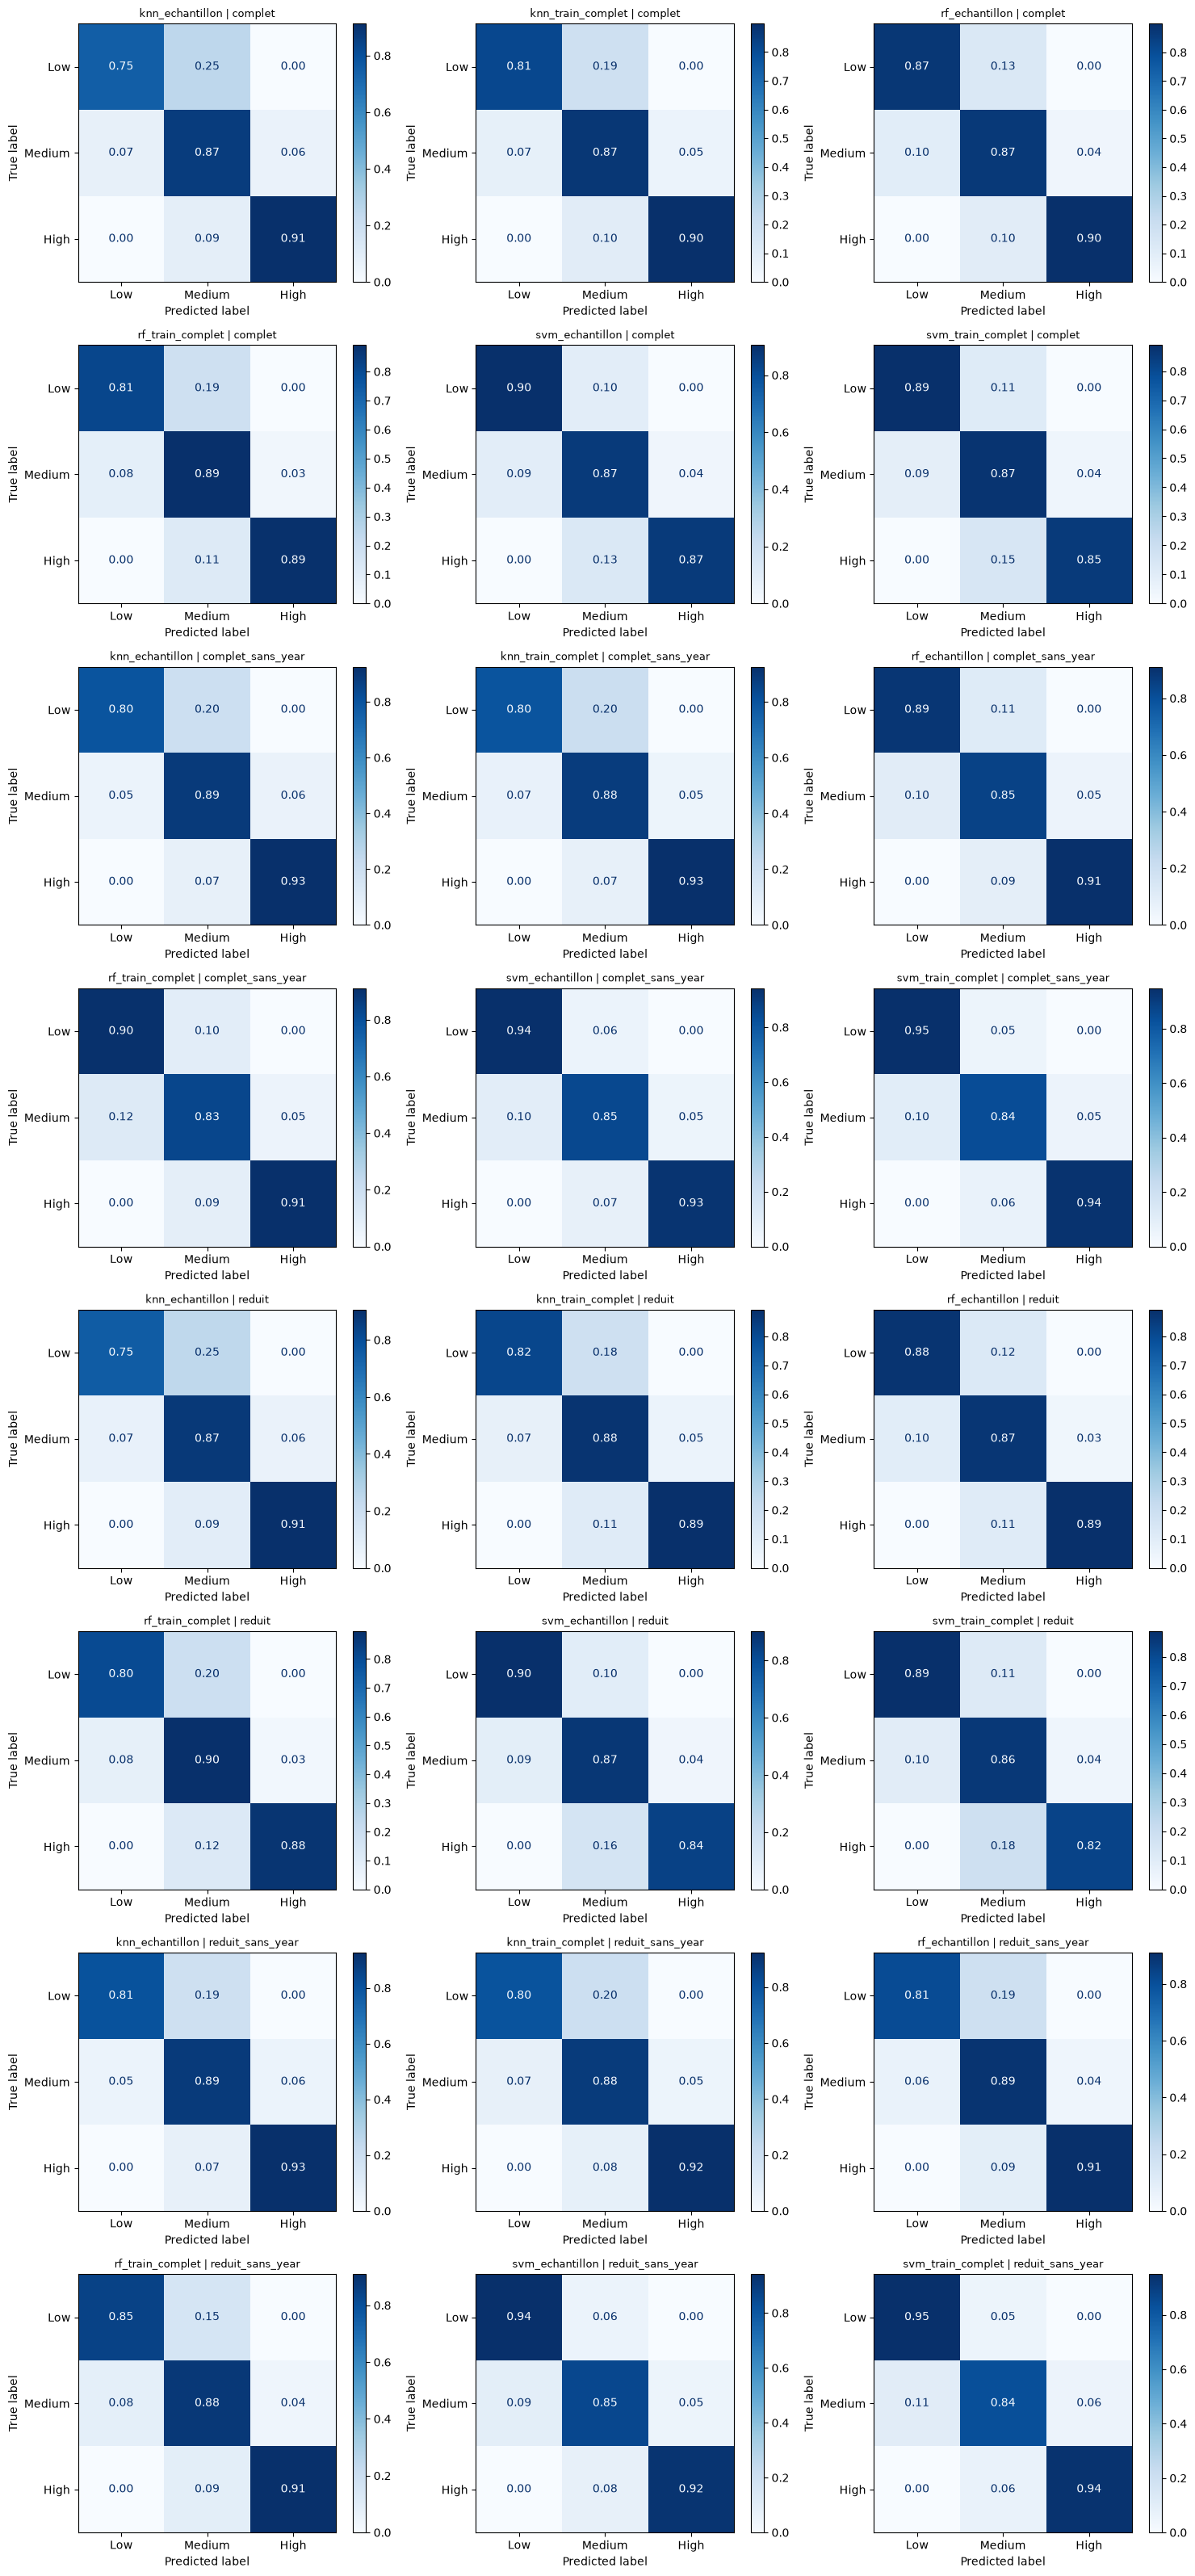

Figure enregistrée : C:\Users\chahi\Desktop\DM-Weather-framework\results\figures\matrices_confusion_supervise.png


In [16]:
noms = list(predictions)
ncols = 3
nrows = int(np.ceil(len(noms) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax in axes[len(noms):]:
    ax.axis("off")
for ax, nom in zip(axes, noms):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[nom], labels=LABELS, normalize="true",
                                            ax=ax, cmap="Blues", values_format=".2f")
    ax.set_title(nom, fontsize=9)
plt.tight_layout()
chemin_fig = os.path.join(FIGURES_DIR, "matrices_confusion_supervise.png")
plt.savefig(chemin_fig, dpi=150)
plt.show()
print("Figure enregistrée :", chemin_fig)

### Score par mois sur le test

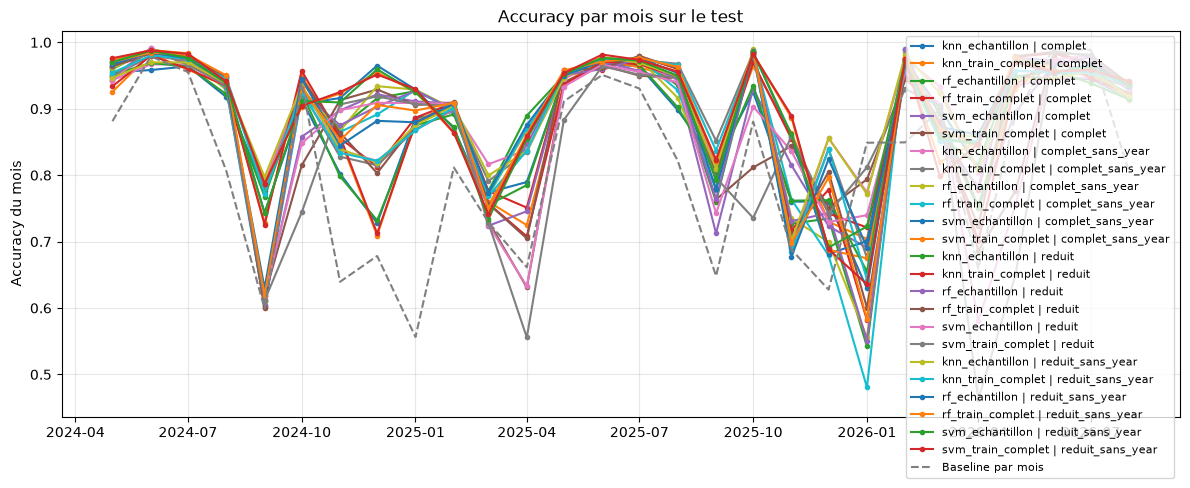

Figure enregistrée : C:\Users\chahi\Desktop\DM-Weather-framework\results\figures\accuracy_par_mois_supervise.png


In [17]:
dates = test["date"].to_numpy()

plt.figure(figsize=(12, 5))
for nom, y_pred in predictions.items():
    accuracy_mois = pd.Series(y_pred == y_test).groupby(dates).mean()
    plt.plot(accuracy_mois.index, accuracy_mois.values, marker="o", markersize=3, label=nom)

accuracy_base = pd.Series(pred_par_mois == y_test).groupby(dates).mean()
plt.plot(accuracy_base.index, accuracy_base.values, linestyle="--", color="gray", label="Baseline par mois")

plt.ylabel("Accuracy du mois")
plt.title("Accuracy par mois sur le test")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
chemin_fig = os.path.join(FIGURES_DIR, "accuracy_par_mois_supervise.png")
plt.savefig(chemin_fig, dpi=150)
plt.show()
print("Figure enregistrée :", chemin_fig)

In [18]:
import glob

fichiers = sorted(glob.glob(os.path.join(MODELES_DIR, "*", "*.pkl")))
if not fichiers:
    print("Aucun modèle pour l'instant. Lance les entraînements de la section 5.")
for chemin in fichiers:
    print(chemin)

C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet\knn_echantillon.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet\knn_train_complet.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet\rf_echantillon.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet\rf_train_complet.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet\svm_echantillon.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet\svm_train_complet.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year\knn_echantillon.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year\knn_train_complet.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year\rf_echantillon.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year\rf_train_complet.pkl
C:\Users\chahi\Desktop\DM-Weather-framework\results\models\complet_sans_year\svm_ech